# 0 Библиотеки

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [ ]:
x = pd.read_csv("https://github.com/koroteevmv/ML_course/raw/main/ML1.2%20multivariate/data/0_x.csv",header=None)
y = pd.read_csv("https://github.com/koroteevmv/ML_course/raw/main/ML1.2%20multivariate/data/0_y.csv",header=None)
x.head()

,0,1,2,3,4
0,0.071841,0.855352,-0.305597,0.028253,1.826895
1,0.139521,-0.423507,0.461059,-0.447400,-0.034988
2,1.626311,-0.257622,-0.697520,1.413219,1.086292
3,-1.183233,-0.826343,0.073047,-0.639690,-0.503273
4,-0.783365,-0.861232,0.951448,-0.117306,0.680597


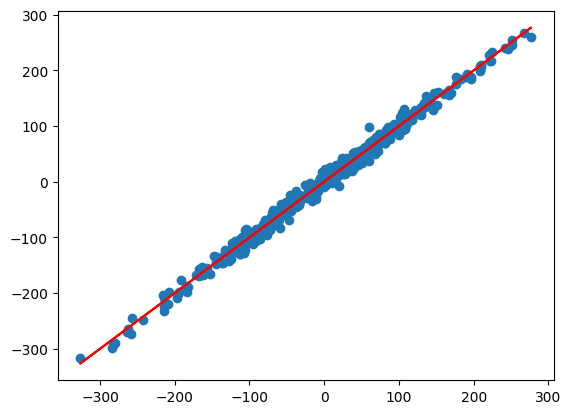

In [ ]:
multiple = LinearRegression()
multiple.fit(x, y)
multiple.score(x, y)
yy = multiple.predict(x)
plt.scatter(yy, y)
plt.plot(yy, yy, c='r')

# 1 Cамостоятельно постройте парные регрессии от каждого атрибута с целевой переменной.

In [ ]:
class Model(object):
    """Модель парной линейной регрессии"""
    def __init__(self):
        self.b0 = 0
        self.b1 = 0
    def predict(self, X):
        return self.b0 + self.b1 * X
    def error(self, X, Y):
        return sum(((self.predict(X) - Y)**2) / (2 * len(X)))
    def fit(self, X, Y=None, alpha=1.0, accuracy=0.01, max_steps=5000):
        #if not(type(Y) == pd.Series):
        #    Y = X.iloc[:,1]
        #    X = X.iloc[:,0]
        steps, errors = [], []
        step = 0
        err = self.error(X, Y)
        for _ in range(10000):
            #print(X)
            dJ0 = sum(self.predict(X) - Y) /len(X)
            dJ1 = sum((self.predict(X) - Y) * X) /len(X)
            self.b0 -= alpha * dJ0
            self.b1 -= alpha * dJ1
            new_err = self.error(X, Y)

            if (new_err>err):
                print('The error is going up!')
                break
            else:
                alpha /= 2
            err = new_err

            step += 1
            steps.append(step)
            errors.append(err)
        return steps, errors

    def draw_regress(self,x,y=None,iters=100):
        #if not(type(y) == pd.Series):
        #    y = x.iloc[:,1]
        #    x = x.iloc[:,0]
        steps, errors = self.fit(x,y,max_steps=iters)
        J = self.error(x, y)
        print("error after gradient descent:", J)
        X0 = np.linspace(round(x.min())-1, round(x.max())+1, round(x.max()-x.min())*100)
        Y0 = self.predict(X0)
        plt.figure()
        plt.scatter(x, y)
        plt.plot(X0, Y0, 'r')
        plt.show()

for i in range(x.shape[0]):
  print(i)
  hyp = Model()
  hyp.draw_regress(x[i],y,iters=100)


Выходные данные были обрезаны до нескольких последних строк (5000).
4     -0.783365
         ...   
382    0.684004
383   -0.430455
384   -0.457141
385   -0.344278
386   -1.349114
Name: 0, Length: 387, dtype: float64
0      0.071841
1      0.139521
2      1.626311
3     -1.183233
4     -0.783365
         ...   
382    0.684004
383   -0.430455
384   -0.457141
385   -0.344278
386   -1.349114
Name: 0, Length: 387, dtype: float64
0      0.071841
1      0.139521
2      1.626311
3     -1.183233
4     -0.783365
         ...   
382    0.684004
383   -0.430455
384   -0.457141
385   -0.344278
386   -1.349114
Name: 0, Length: 387, dtype: float64
0      0.071841
1      0.139521
2      1.626311
3     -1.183233
4     -0.783365
         ...   
382    0.684004
383   -0.430455
384   -0.457141
385   -0.344278
386   -1.349114
Name: 0, Length: 387, dtype: float64
0      0.071841
1      0.139521
2      1.626311
3     -1.183233
4     -0.783365
         ...   
382    0.684004
383   -0.430455
384   -0.457141


KeyboardInterrupt: 

In [ ]:
Model().draw_regress(x[0],y)

# 2 (*) Модифицируйте код из предыдущей работы так, чтобы модель регрессии умела работать с входными данными, состоящими из произвольного количества столбцов.

# 5 Используйте другие метрики качества регрессионной модели в дополнение к коэффициенту детерминации.

# 6 (*) Замерьте время обучения полиномиальных моделей с разной степенью полинома. Сделайте вывод.